# Crick AF3 installation VS AF3 Server.  

Comparison of the results of cofolding for a small set of control proteins between the Crick AF3 installation and the AF3 Server.  The control set was derived from (Vo et al.) and included all the interactions specifically highlighted in the text, all the interactions that had both Y2H and followup PCA evidence from their positive interaction list, and then additional interactions that either had Y2H or PCA evidence.  We also included interactions from the negative control list and 3 interactions from proteins under specific investigation by Melania and Shaima.  

The overall total is 23 positive interactions, 5  negative interactions and 3 predicted but unknown interactions.  

Alphafold Server was run on 24 July 2026 except for Shaimaa's interaction (which she ran earlier in the year) and Rea1/ATP23 which was run on 22 July 2026.  We also have an older Rea1/ATP23 version. 

Yew Mun Yip used input from a Fasta file created here and code he wrote to run alphastream on all the pairs over the weekend starting from 24 July 2026.  

? Was it run on an updated version of Alphafold3 or the old version?





In [1]:
import os
import pandas as pd
import json
import re
from pathlib import Path
import importlib
import unstudied_gene_tools as usg
importlib.reload(usg)

# Define file paths and data directories
BASE_DATA_DIR = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes"
CRICK_BASE_DATA_DIR = r"C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test"

# Input data files
GENE_DATA_FILE = os.path.join(BASE_DATA_DIR, "gene_IDs_names_products.tsv")

# Alpha pulldown screen data
ALPHAPULLDOWN_DATA_DIR = os.path.join(BASE_DATA_DIR, "ppis", "ppi_screen")
POMBE_INTERACTION_SMALL_TEST_FILE = os.path.join(ALPHAPULLDOWN_DATA_DIR, "pombe_interaction_small_test.csv")

## Prepare list of proteins with Uniprot IDs and fastas
output is a fasta file provided to Yew Mun's alphastream routine. 

In [2]:
# Load the gene data file
gene_df = pd.read_csv(GENE_DATA_FILE, sep='\t')

# Create a mapping from systematic ID to uniprot_id and gene_name
# The IDs might have case variations, so normalize them for matching
gene_mapping = {}
for _, row in gene_df.iterrows():
    sys_id = row['gene_systematic_id'].upper()  # Normalize to uppercase for matching
    gene_mapping[sys_id] = {
        'uniprot_id': row['uniprot_id'],
        'gene_name': row['gene_name']
    }

# Load the interaction file
interactions_df = pd.read_csv(POMBE_INTERACTION_SMALL_TEST_FILE)

# Function to look up gene info
def lookup_gene_info(orf):
    """Look up uniprot_id and gene_name for an ORF"""
    orf_upper = orf.upper()
    if orf_upper in gene_mapping:
        info = gene_mapping[orf_upper]
        return info['uniprot_id'], info['gene_name']
    else:
        return None, None

# Add the new columns
interactions_df[['uniprot_id_A', 'gene_name_A']] = interactions_df['ORF_A'].apply(
    lambda x: pd.Series(lookup_gene_info(x))
)
interactions_df[['uniprot_id_B', 'gene_name_B']] = interactions_df['ORF_B'].apply(
    lambda x: pd.Series(lookup_gene_info(x))
)

# Display the result
print(f"Added {len(interactions_df)} rows with gene info")
print(f"Columns: {interactions_df.columns.tolist()}")
print("\nFirst few rows:")
print(interactions_df.head())

Added 31 rows with gene info
Columns: ['ORF_A', 'ORF_B', 'Y2H_status', 'PCA_status', 'Notes', 'uniprot_id_A', 'gene_name_A', 'uniprot_id_B', 'gene_name_B']

First few rows:
          ORF_A        ORF_B  Y2H_status  PCA_status  \
0   SPAC227.17C   SPCC320.12  not tested  not tested   
1   SPBC25H2.14  SPBC1539.05  not tested  not tested   
2  SPCC1494.08C  SPAC3H5.09c  not tested  not tested   
3    SPBC83.03C   SPBC3H7.15  not tested  not tested   
4   SPBC29B5.01   SPCC663.12  not tested  not tested   

                                      Notes uniprot_id_A gene_name_A  \
0                 Melania's gene rea1/atp23       Q9UTC2         NaN   
1                 Melania's gene mug16/cog3       P87155       mug16   
2                            Shaimaa's Gene       O60082         NaN   
3   tas3/hhp1 interaction shown in vo et al       O94687        tas3   
4  atf1/cid12 interaction shown in vo et al       P52890        atf1   

  uniprot_id_B gene_name_B  
0       Q1MTR0       atp23  

In [3]:
# Add the uniprot and gene_name columns again
interactions_df[['uniprot_id_A', 'gene_name_A']] = interactions_df['ORF_A'].apply(
    lambda x: pd.Series(lookup_gene_info(x))
)
interactions_df[['uniprot_id_B', 'gene_name_B']] = interactions_df['ORF_B'].apply(
    lambda x: pd.Series(lookup_gene_info(x))
)

# Create new filename with _UNIPROT suffix
original_file = POMBE_INTERACTION_SMALL_TEST_FILE
# Split the filename to insert _UNIPROT before .csv
base_name = original_file.rsplit('.', 1)[0]  # Remove extension
new_filename = f"{base_name}_UNIPROT.csv"

# Save to the new file
interactions_df.to_csv(new_filename, index=False)
print(f"✓ Created new file: {new_filename}")
print(f"\nFile contents:")
print(f"  Rows: {len(interactions_df)}")
print(f"  Columns: {interactions_df.columns.tolist()}")
print(f"\nFirst few rows:")
print(interactions_df.head())

✓ Created new file: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test_UNIPROT.csv

File contents:
  Rows: 31
  Columns: ['ORF_A', 'ORF_B', 'Y2H_status', 'PCA_status', 'Notes', 'uniprot_id_A', 'gene_name_A', 'uniprot_id_B', 'gene_name_B']

First few rows:
          ORF_A        ORF_B  Y2H_status  PCA_status  \
0   SPAC227.17C   SPCC320.12  not tested  not tested   
1   SPBC25H2.14  SPBC1539.05  not tested  not tested   
2  SPCC1494.08C  SPAC3H5.09c  not tested  not tested   
3    SPBC83.03C   SPBC3H7.15  not tested  not tested   
4   SPBC29B5.01   SPCC663.12  not tested  not tested   

                                      Notes uniprot_id_A gene_name_A  \
0                 Melania's gene rea1/atp23       Q9UTC2         NaN   
1                 Melania's gene mug16/cog3       P87155       mug16   
2                            Shaimaa's Gene       O60082         NaN   
3   tas3/hhp1 interaction shown in vo et al       O94687        tas3   
4  a

In [4]:
import gzip
from Bio.PDB import PDBParser
import unstudied_gene_tools as usg

# Get unique UniProt IDs from both columns, excluding NaNs
uniprot_ids = set()
uniprot_ids.update(interactions_df['uniprot_id_A'].dropna())
uniprot_ids.update(interactions_df['uniprot_id_B'].dropna())
uniprot_ids = sorted(list(uniprot_ids))

print(f"Found {len(uniprot_ids)} unique UniProt IDs to extract sequences for")
print(f"UniProt IDs: {uniprot_ids}")

# Directory with AlphaFold structures
alphafold_dir = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\UP000002485_284812_SCHPO_v6"

# Extract sequences for each UniProt ID
sequences = {}
for uniprot_id in uniprot_ids:
    # Construct the expected filename
    pdb_file_gz = f"AF-{uniprot_id}-F1-model_v6.pdb.gz"
    pdb_path = os.path.join(alphafold_dir, pdb_file_gz)
    
    if os.path.exists(pdb_path):
        try:
            # Read the gzipped PDB file
            with gzip.open(pdb_path, 'rt') as f:
                pdb_content = f.read()
            
            # Extract sequence using the utility function
            sequence = usg.extract_sequence_from_pdb(pdb_content)
            sequences[uniprot_id] = sequence
            print(f"✓ {uniprot_id}: {len(sequence)} residues")
        except Exception as e:
            print(f"✗ Error processing {uniprot_id}: {e}")
    else:
        print(f"✗ File not found: {pdb_file_gz}")

print(f"\n✓ Successfully extracted sequences for {len(sequences)}/{len(uniprot_ids)} proteins")

Found 51 unique UniProt IDs to extract sequences for
UniProt IDs: ['O13828', 'O14092', 'O14176', 'O42634', 'O43114', 'O60082', 'O74518', 'O94273', 'O94376', 'O94687', 'P01129', 'P33886', 'P36601', 'P36616', 'P36618', 'P40235', 'P40995', 'P40996', 'P41410', 'P41412', 'P41892', 'P42881', 'P52890', 'P53692', 'P78794', 'P78814', 'P79005', 'P87027', 'P87155', 'Q09142', 'Q09683', 'Q09824', 'Q09892', 'Q09911', 'Q10103', 'Q10193', 'Q10951', 'Q1MTR0', 'Q4PIR3', 'Q6LA55', 'Q9HDV5', 'Q9P805', 'Q9US43', 'Q9USH5', 'Q9UT18', 'Q9UTC2', 'Q9UU85', 'Q9UUF1', 'Q9UUK1', 'Q9Y7S8', 'Q9Y7Z4']
✓ O13828: 741 residues
✓ O14092: 558 residues
✓ O14176: 695 residues
✓ O42634: 332 residues
✓ O43114: 455 residues
✓ O60082: 274 residues
✓ O74518: 336 residues
✓ O94273: 201 residues
✓ O94376: 138 residues
✓ O94687: 549 residues
✓ P01129: 767 residues
✓ P33886: 605 residues
✓ P36601: 365 residues
✓ P36616: 544 residues
✓ P36618: 299 residues
✓ P40235: 365 residues
✓ P40995: 872 residues
✓ P40996: 536 residues
✓ P41410:

In [23]:
# Write FASTA file
fasta_output = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test.fasta"

with open(fasta_output, 'w') as fasta_file:
    for uniprot_id in uniprot_ids:
        if uniprot_id in sequences:
            sequence = sequences[uniprot_id]
            # Write FASTA header
            fasta_header = f">{uniprot_id}"
            fasta_file.write(fasta_header + '\n')
            # Write sequence as a single line
            fasta_file.write(sequence + '\n')

print(f"✓ FASTA file saved to: {fasta_output}")
print(f"  Total sequences: {len(sequences)}")
print(f"  Total residues: {sum(len(seq) for seq in sequences.values())}")
print(f"\nFirst 5 entries (header only) in FASTA file:")
with open(fasta_output, 'r') as f:
    lines = f.readlines()
    header_count = 0
    for line in lines:
        if line.startswith('>'):
            print(line.rstrip())
            header_count += 1
            if header_count >= 5:
                break

✓ FASTA file saved to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test.fasta
  Total sequences: 51
  Total residues: 26376

First 5 entries (header only) in FASTA file:
>O13828
>O14092
>O14176
>O42634
>O43114


In [24]:
# Read the combined FASTA file and create a dictionary of sequences
fasta_sequences = {}
with open(fasta_output, 'r') as f:
    current_id = None
    for line in f:
        line = line.rstrip()
        if line.startswith('>'):
            current_id = line[1:]  # Remove '>' and get the UniProt ID
        else:
            if current_id:
                fasta_sequences[current_id] = line

print(f"✓ Loaded {len(fasta_sequences)} sequences from combined FASTA file")

# Write FASTA files for Protein A and B, maintaining order and pairing from interactions_df
fasta_output_a = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test_A.fasta"
fasta_output_b = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test_B.fasta"

# Open both files for writing
with open(fasta_output_a, 'w') as fasta_a, open(fasta_output_b, 'w') as fasta_b:
    # Iterate through interactions_df in order
    for idx, row in interactions_df.iterrows():
        uniprot_id_a = row['uniprot_id_A']
        uniprot_id_b = row['uniprot_id_B']
        
        # Write Protein A entry if not NaN
        if pd.notna(uniprot_id_a):
            if uniprot_id_a in fasta_sequences:
                sequence_a = fasta_sequences[uniprot_id_a]
                fasta_a.write(f">{uniprot_id_a}\n")
                fasta_a.write(f"{sequence_a}\n")
            else:
                print(f"⚠ Warning: {uniprot_id_a} from row {idx} not found in sequences")
        
        # Write Protein B entry if not NaN
        if pd.notna(uniprot_id_b):
            if uniprot_id_b in fasta_sequences:
                sequence_b = fasta_sequences[uniprot_id_b]
                fasta_b.write(f">{uniprot_id_b}\n")
                fasta_b.write(f"{sequence_b}\n")
            else:
                print(f"⚠ Warning: {uniprot_id_b} from row {idx} not found in sequences")

print(f"\n✓ FASTA files created with paired order from interactions_df")
print(f"\n✓ FASTA file for Protein A saved to: {fasta_output_a}")
a_count = len(interactions_df[interactions_df['uniprot_id_A'].notna()])
print(f"  Total entries: {a_count}")
a_residues = sum(len(fasta_sequences.get(uid, '')) for uid in interactions_df['uniprot_id_A'].dropna())
print(f"  Total residues: {a_residues}")

print(f"\n✓ FASTA file for Protein B saved to: {fasta_output_b}")
b_count = len(interactions_df[interactions_df['uniprot_id_B'].notna()])
print(f"  Total entries: {b_count}")
b_residues = sum(len(fasta_sequences.get(uid, '')) for uid in interactions_df['uniprot_id_B'].dropna())
print(f"  Total residues: {b_residues}")

✓ Loaded 51 sequences from combined FASTA file

✓ FASTA files created with paired order from interactions_df

✓ FASTA file for Protein A saved to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test_A.fasta
  Total entries: 31
  Total residues: 13934

✓ FASTA file for Protein B saved to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppi_screen\pombe_interaction_small_test_B.fasta
  Total entries: 31
  Total residues: 17704


# AlphaFold3 Server Cofolding Data Analysis

Extract and process summary confidence data from AlphaFold3 Server cofolding runs.
Each protein pair has up to 5 runs (0-4) with summary confidence metrics.


In [13]:


# Define paths for AlphaFold3 Server data
AF3_SERVER_DIR = os.path.join(CRICK_BASE_DATA_DIR, "af3_server")
REFERENCE_CSV = os.path.join(CRICK_BASE_DATA_DIR, "pombe_interaction_small_test_UNIPROT.csv")

# Define output path (same directory)
OUTPUT_CSV = os.path.join(AF3_SERVER_DIR, "af3_server_cofolding_data.csv")

print(f"AF3 Server directory: {AF3_SERVER_DIR}")
print(f"Reference CSV: {REFERENCE_CSV}")
print(f"Output will be saved to: {OUTPUT_CSV}")


AF3 Server directory: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af3_server
Reference CSV: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\pombe_interaction_small_test_UNIPROT.csv
Output will be saved to: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af3_server\af3_server_cofolding_data.csv


In [13]:
# Rename files in folders with old naming convention

rename_mapping = {'p87155_q9y7z4_2026_04_24_11_05': 'mug16_cog3_2026_04_24_11_05'}
#'o60082_q6la55_2026_00_00_00_00':'gened_vs_hob2', 
#'q9utc2_q1mtr0_2026_07_22_00_00': 'rea1_atp23_22jul26', 
#'q9utc2_q1mtr0_2026_04_24_10_28':'rea1_atp23_2026_04_24_10_28', 
#'q9utc2_q1mtr0_2025_11_26_13_55': '2025_11_26_13_55_spac227_17c_spcc320_12'


print("Updating filenames for folders with old naming convention...")
print(f"{'='*70}\n")

for folder_name, old_name_pattern in rename_mapping.items():
    folder_path = Path(AF3_SERVER_DIR) / folder_name
    
    if not folder_path.exists():
        print(f"⚠ Folder not found: {folder_name}")
        continue
    
    print(f"Processing folder: {folder_name}")
    print(f"  Replacing: {old_name_pattern}")
    print(f"  With: {folder_name}")
    
    renamed_count = 0
    for old_file in folder_path.iterdir():
        if old_file.is_file() and old_name_pattern in old_file.name:
            new_filename = old_file.name.replace(old_name_pattern, folder_name)
            new_file = folder_path / new_filename
            
            try:
                old_file.rename(new_file)
                print(f"    ✓ {old_file.name} → {new_filename}")
                renamed_count += 1
            except Exception as e:
                print(f"    ✗ Error renaming {old_file.name}: {e}")
    
    print(f"  Total files renamed: {renamed_count}\n")

print(f"{'='*70}")
print("✓ File renaming complete!")

#Note:   q9utc2_q1mtr0_2025_11_26_13_55 only had 15 files renamed - it looked like the full data file was in the folder but with a different name - it had just had fold_<base_folder_name>.  I added the suffix _full_data_0 so that it would be similar to the others. 


Updating filenames for folders with old naming convention...

Processing folder: p87155_q9y7z4_2026_04_24_11_05
  Replacing: mug16_cog3_2026_04_24_11_05
  With: p87155_q9y7z4_2026_04_24_11_05
    ✓ fold_mug16_cog3_2026_04_24_11_05_full_data_0.json → fold_p87155_q9y7z4_2026_04_24_11_05_full_data_0.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_full_data_1.json → fold_p87155_q9y7z4_2026_04_24_11_05_full_data_1.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_full_data_2.json → fold_p87155_q9y7z4_2026_04_24_11_05_full_data_2.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_full_data_3.json → fold_p87155_q9y7z4_2026_04_24_11_05_full_data_3.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_full_data_4.json → fold_p87155_q9y7z4_2026_04_24_11_05_full_data_4.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_job_request.json → fold_p87155_q9y7z4_2026_04_24_11_05_job_request.json
    ✓ fold_mug16_cog3_2026_04_24_11_05_model_0.cif → fold_p87155_q9y7z4_2026_04_24_11_05_model_0.cif
    ✓ fold_mug16_cog3_2026_04_24_11_05_mo

In [ ]:
# Define regex pattern to match folder names
# Pattern: <uniprot_ID_A>_<uniprot_ID_B>_<YYYY>_<MM>_<DD>_<HH>_<MM>
folder_pattern = re.compile(r'^([A-Za-z0-9]+)_([A-Za-z0-9]+)_(\d{4})_(\d{2})_(\d{2})_(\d{2})_(\d{2})$')

# Define regex pattern for JSON files
# Pattern: fold_<uniprot_ID_A>_<uniprot_ID_B>_<YYYY>_<MM>_<DD>_<HH>_<MM>_summary_confidences_<run_number>.json
json_pattern = re.compile(r'^fold_[A-Za-z0-9]+_[A-Za-z0-9]+_\d{4}_\d{2}_\d{2}_\d{2}_\d{2}_summary_confidences_(\d)\.json$')

# Scan the AF3_SERVER_DIR
cofolding_data = []
processed_folders = []

af3_path = Path(AF3_SERVER_DIR)
print(f"\nScanning {AF3_SERVER_DIR}...")

for folder in sorted(af3_path.iterdir()):
    if not folder.is_dir():
        continue
    
    folder_name = folder.name
    match = folder_pattern.match(folder_name)
    
    if not match:
        print(f"⚠ Skipping folder (incorrect format): {folder_name}")
        continue
    
    uniprot_a, uniprot_b, year, month, day, hour, minute = match.groups()
    date_str = f"{year}{month}{day}"
    
    # Convert to uppercase as per requirements
    uniprot_a = uniprot_a.upper()
    uniprot_b = uniprot_b.upper()
    
    processed_folders.append((uniprot_a, uniprot_b))
    
    # Look for JSON files (runs 0-4)
    for run_number in range(5):
        # Construct expected JSON filename
        json_filename = f"fold_{uniprot_a}_{uniprot_b}_{year}_{month}_{day}_{hour}_{minute}_summary_confidences_{run_number}.json"
        json_path = folder / json_filename
        
        if json_path.exists():
            try:
                with open(json_path, 'r') as f:
                    json_data = json.load(f)
                
                # Extract required fields
                row_data = {
                    'uniprot_ID_A': uniprot_a,
                    'uniprot_ID_B': uniprot_b,
                    'date': date_str,
                    'run_number': run_number,
                    'fraction_disordered': json_data.get('fraction_disordered', None),
                    'has_clash': json_data.get('has_clash', None),
                    'iptm': json_data.get('iptm', None),
                    'ptm': json_data.get('ptm', None),
                    'ranking_score': json_data.get('ranking_score', None)
                }
                cofolding_data.append(row_data)
                
            except Exception as e:
                print(f"✗ Error reading {json_filename}: {e}")
        else:
            print(f"⚠ Missing JSON file: {json_filename}")

# Create DataFrame
cofolding_df = pd.DataFrame(cofolding_data)

print(f"\n✓ Processed {len(processed_folders)} folders")
print(f"✓ Extracted data from {len(af3server_cofolding_df)} JSON files")
print(f"\nDataFrame shape: {af3server_cofolding_df.shape}")
print(f"Columns: {af3server_cofolding_df.columns.tolist()}")
print(f"\nFirst few rows:")
print(af3server_cofolding_df.head(10))



Scanning C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af3_server...

✓ Processed 35 folders
✓ Extracted data from 175 JSON files

DataFrame shape: (175, 9)
Columns: ['uniprot_ID_A', 'uniprot_ID_B', 'date', 'run_number', 'fraction_disordered', 'has_clash', 'iptm', 'ptm', 'ranking_score']

First few rows:
  uniprot_ID_A uniprot_ID_B      date  run_number  fraction_disordered  \
0       O13828       Q9P805  20260724           0                 0.55   
1       O13828       Q9P805  20260724           1                 0.55   
2       O13828       Q9P805  20260724           2                 0.53   
3       O13828       Q9P805  20260724           3                 0.54   
4       O13828       Q9P805  20260724           4                 0.52   
5       O42634       O42634  20260724           0                 0.04   
6       O42634       O42634  20260724           1                 0.04   
7       O42634       O

In [ ]:
# Load reference CSV
reference_df = pd.read_csv(REFERENCE_CSV)

print(f"✓ Loaded reference CSV: {len(reference_df)} rows")
print(f"\nReference columns: {reference_df.columns.tolist()}")
print(f"\nFirst few rows of reference data:")
print(reference_df.head())

# Convert to uppercase for comparison (as per requirements)
reference_df['uniprot_id_A_upper'] = reference_df['uniprot_id_A'].str.upper()
reference_df['uniprot_id_B_upper'] = reference_df['uniprot_id_B'].str.upper()

# Create set of expected protein pairs from reference
expected_pairs = set()
for _, row in reference_df.iterrows():
    pair = (row['uniprot_id_A_upper'], row['uniprot_id_B_upper'])
    expected_pairs.add(pair)

print(f"\n✓ Expected {len(expected_pairs)} unique protein pairs from reference CSV")


✓ Loaded reference CSV: 31 rows

Reference columns: ['ORF_A', 'ORF_B', 'Y2H_status', 'PCA_status', 'Notes', 'uniprot_id_A', 'gene_name_A', 'uniprot_id_B', 'gene_name_B']

First few rows of reference data:
          ORF_A        ORF_B  Y2H_status  PCA_status  \
0   SPAC227.17C   SPCC320.12  not tested  not tested   
1   SPBC25H2.14  SPBC1539.05  not tested  not tested   
2  SPCC1494.08C  SPAC3H5.09c  not tested  not tested   
3    SPBC83.03C   SPBC3H7.15  not tested  not tested   
4   SPBC29B5.01   SPCC663.12  not tested  not tested   

                                      Notes uniprot_id_A gene_name_A  \
0                 Melania's gene rea1/atp23       Q9UTC2         NaN   
1                 Melania's gene mug16/cog3       P87155       mug16   
2                            Shaimaa's Gene       O60082         NaN   
3   tas3/hhp1 interaction shown in vo et al       O94687        tas3   
4  atf1/cid12 interaction shown in vo et al       P52890        atf1   

  uniprot_id_B gene_name_

In [ ]:
# Compare processed folders with expected pairs
processed_pairs = set(processed_folders)

print(f"\n{'='*70}")
print("VALIDATION REPORT")
print(f"{'='*70}")

# Find missing pairs
missing_pairs = expected_pairs - processed_pairs
print(f"\n✗ MISSING PROTEIN PAIRS: {len(missing_pairs)}")
if missing_pairs:
    print("\nProtein pairs in reference CSV but NOT in af3_server directory:")
    for uniprot_a, uniprot_b in sorted(missing_pairs):
        print(f"  - {uniprot_a} × {uniprot_b}")
else:
    print("  ✓ All expected protein pairs have data!")

# Find extra pairs (in af3_server but not in reference)
extra_pairs = processed_pairs - expected_pairs
print(f"\n⚠ EXTRA PROTEIN PAIRS (not in reference): {len(extra_pairs)}")
if extra_pairs:
    print("\nProtein pairs in af3_server but NOT in reference CSV:")
    for uniprot_a, uniprot_b in sorted(extra_pairs):
        print(f"  - {uniprot_a} × {uniprot_b}")

# Summary
print(f"\n{'='*70}")
print("SUMMARY")
print(f"{'='*70}")
print(f"Expected pairs (from reference): {len(expected_pairs)}")
print(f"Found pairs (in af3_server): {len(processed_pairs)}")
print(f"Complete pairs: {len(expected_pairs & processed_pairs)}")
print(f"Missing pairs: {len(missing_pairs)}")
print(f"Extra pairs: {len(extra_pairs)}")
print(f"\nDataFrame rows (5 runs × number of pairs): {len(af3server_cofolding_df)}")



VALIDATION REPORT

✗ MISSING PROTEIN PAIRS: 0
  ✓ All expected protein pairs have data!

⚠ EXTRA PROTEIN PAIRS (not in reference): 0

SUMMARY
Expected pairs (from reference): 31
Found pairs (in af3_server): 31
Complete pairs: 31
Missing pairs: 0
Extra pairs: 0

DataFrame rows (5 runs × number of pairs): 175


In [ ]:
# Save the cofolding data to CSV
af3server_cofolding_df.to_csv(OUTPUT_CSV, index=False)

print(f"\n✓ Cofolding data saved to: {OUTPUT_CSV}")
print(f"\nOutput CSV summary:")
print(f"  Rows: {len(af3server_cofolding_df)}")
print(f"  Columns: {', '.join(af3server_cofolding_df.columns.tolist())}")
print(f"\nData types:")
print(af3server_cofolding_df.dtypes)
print(f"\nStatistical summary:")
print(af3server_cofolding_df.describe())



✓ Cofolding data saved to: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af3_server\af3_server_cofolding_data.csv

Output CSV summary:
  Rows: 175
  Columns: uniprot_ID_A, uniprot_ID_B, date, run_number, fraction_disordered, has_clash, iptm, ptm, ranking_score

Data types:
uniprot_ID_A            object
uniprot_ID_B            object
date                    object
run_number               int64
fraction_disordered    float64
has_clash              float64
iptm                   float64
ptm                    float64
ranking_score          float64
dtype: object

Statistical summary:
       run_number  fraction_disordered  has_clash        iptm         ptm  \
count  175.000000           175.000000      175.0  175.000000  175.000000   
mean     2.000000             0.294514        0.0    0.499714    0.521600   
std      1.418272             0.185753        0.0    0.263514    0.155467   
min      0.000000      

# Alphastream Installation Cofolding Data Analysis

Extract and process summary confidence data from Alphastream installation cofolding runs.
Each protein pair has multiple runs with different seeds and samples.


In [43]:
# Define paths for the two Alphastream iterations
ALPHASTREAM_OLD_DIR = os.path.join(CRICK_BASE_DATA_DIR, "small_control_test")
ALPHASTREAM_NEW_DIR = r"\\?\\" + os.path.join(CRICK_BASE_DATA_DIR, "af303_settings_similar_to_afserver")

# Keep the original variable name for downstream cells that still use it.
ALPHASTREAM_DIR = ALPHASTREAM_OLD_DIR

ALPHASTREAM_OLD_OUTPUT_CSV = os.path.join(ALPHASTREAM_OLD_DIR, "alphastream_cofolding_data.csv")
ALPHASTREAM_NEW_OUTPUT_CSV = os.path.join(ALPHASTREAM_NEW_DIR, "alphastream_cofolding_data.csv")

print(f"Old Alphastream directory: {ALPHASTREAM_OLD_DIR}")
print(f"New Alphastream directory: {ALPHASTREAM_NEW_DIR}")
print(f"Old output will be saved to: {ALPHASTREAM_OLD_OUTPUT_CSV}")
print(f"New output will be saved to: {ALPHASTREAM_NEW_OUTPUT_CSV}")

# Process both Alphastream runs using the shared helper.
alphastream_old_cofolding_df = usg.process_alphastream_output(
    ALPHASTREAM_OLD_DIR,
    ALPHASTREAM_OLD_DIR,
)
alphastream_new_cofolding_df = usg.process_alphastream_output(
    ALPHASTREAM_NEW_DIR,
    ALPHASTREAM_NEW_DIR,
)

# Preserve the original name for the existing downstream analysis cells.
alphastream_cofolding_df = alphastream_old_cofolding_df

print(f"\n✓ Old Alphastream dataframe rows: {len(alphastream_old_cofolding_df)}")
print(f"✓ New Alphastream dataframe rows: {len(alphastream_new_cofolding_df)}")
print(f"✓ Backward-compatible alias alphastream_cofolding_df now points to the old dataset")

Old Alphastream directory: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\small_control_test
New Alphastream directory: \\?\\C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af303_settings_similar_to_afserver
Old output will be saved to: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\small_control_test\alphastream_cofolding_data.csv
New output will be saved to: \\?\\C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af303_settings_similar_to_afserver\alphastream_cofolding_data.csv

Scanning C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\small_control_test...
⚠ Skipping folder (incorrect format): af_input
⚠ Sk

# Comparison: AF3 Server vs Alphastream

Compare cofolding metrics between the two AlphaFold3 installations.
Generate summary statistics for each protein pair and installation.


In [3]:
# Create summary statistics for AF3 Server data
print("Generating summary statistics for AF3 Server data...")

AF3_SERVER_DIR = os.path.join(CRICK_BASE_DATA_DIR, "af3_server")
af3server_cofolding_df = pd.read_csv(os.path.join(AF3_SERVER_DIR, "af3_server_cofolding_data.csv"))

af3server_summary = af3server_cofolding_df.groupby(['uniprot_ID_A', 'uniprot_ID_B']).agg({
    'fraction_disordered': ['mean', 'std'],
    'has_clash': 'max',
    'iptm': ['mean', 'std'],
    'ptm': ['mean', 'std'],
    'ranking_score': ['mean', 'std']
}).reset_index()

# Flatten column names
af3server_summary.columns = ['uniprot_ID_A', 'uniprot_ID_B', 
                             'af3server_mean_fraction_disordered',
                             'af3server_std_fraction_disordered',
                             'af3server_max_has_clash',
                             'af3server_mean_iptm',
                             'af3server_std_iptm',
                             'af3server_mean_ptm',
                             'af3server_std_ptm',
                             'af3server_mean_ranking_score',
                             'af3server_std_ranking_score']

print(f"✓ AF3 Server summary: {len(af3server_summary)} unique protein pairs")
print(f"\nFirst few rows:")
print(af3server_summary.head())
print(f"\nAF3 Server summary columns: {af3server_summary.columns.tolist()}")


Generating summary statistics for AF3 Server data...
✓ AF3 Server summary: 31 unique protein pairs

First few rows:
  uniprot_ID_A uniprot_ID_B  af3server_mean_fraction_disordered  \
0       O13828       Q9P805                               0.538   
1       O42634       O42634                               0.040   
2       O43114       Q09142                               0.258   
3       O60082       Q6LA55                               0.119   
4       O94273       Q9Y7S8                               0.430   

   af3server_std_fraction_disordered  af3server_max_has_clash  \
0                           0.013038                      0.0   
1                           0.000000                      0.0   
2                           0.008367                      0.0   
3                           0.019120                      0.0   
4                           0.018708                      0.0   

   af3server_mean_iptm  af3server_std_iptm  af3server_mean_ptm  \
0                0.950  

In [ ]:
# Create summary statistics for original Alphastream data
print("\nGenerating summary statistics for original Alphastream data...")

ALPHASTREAM_OLD_DIR = os.path.join(CRICK_BASE_DATA_DIR, "small_control_test")
alphastream_cofolding_df_old = pd.read_csv(os.path.join(ALPHASTREAM_OLD_DIR, "alphastream_cofolding_data.csv"))


alphastream_summary_old = alphastream_cofolding_df_old.groupby(['uniprot_ID_A', 'uniprot_ID_B']).agg({
    'fraction_disordered': ['mean', 'std'],
    'has_clash': 'max',
    'iptm': ['mean', 'std'],
    'ptm': ['mean', 'std'],
    'ranking_score': ['mean', 'std']
}).reset_index()

# Flatten column names
alphastream_summary_old.columns = ['uniprot_ID_A', 'uniprot_ID_B', 
                               'alphastream_mean_fraction_disordered',
                               'alphastream_std_fraction_disordered',
                               'alphastream_max_has_clash',
                               'alphastream_mean_iptm',
                               'alphastream_std_iptm',
                               'alphastream_mean_ptm',
                               'alphastream_std_ptm',
                               'alphastream_mean_ranking_score',
                               'alphastream_std_ranking_score']

print(f"✓ Original Alphastream summary : {len(alphastream_summary_old)} unique protein pairs")
print(f"\nFirst few rows:")
print(alphastream_summary_old.head())
print(f"\nOriginal Alphastream summary columns: {alphastream_summary_old.columns.tolist()}")



Generating summary statistics for original Alphastream data...
✓ Original Alphastream summary : 31 unique protein pairs

First few rows:
  uniprot_ID_A uniprot_ID_B  alphastream_mean_fraction_disordered  \
0       O13828       Q9P805                                 0.546   
1       O42634       O42634                                 0.040   
2       O43114       Q09142                                 0.240   
3       O60082       Q6LA55                                 0.068   
4       O94273       Q9Y7S8                                 0.500   

   alphastream_std_fraction_disordered  alphastream_max_has_clash  \
0                             0.005477                        0.0   
1                             0.000000                        0.0   
2                             0.014142                        0.0   
3                             0.008367                        0.0   
4                             0.033166                        0.0   

   alphastream_mean_iptm  alphas

In [7]:
# Create summary statistics for original Alphastream data
print("\nGenerating summary statistics for original Alphastream data...")

ALPHASTREAM_NEW_DIR = r"\\?\\" + os.path.join(CRICK_BASE_DATA_DIR, "af303_settings_similar_to_afserver")
alphastream_cofolding_df_new = pd.read_csv(os.path.join(ALPHASTREAM_NEW_DIR, "alphastream_cofolding_data.csv"))

alphastream_summary_new = alphastream_cofolding_df_new.groupby(['uniprot_ID_A', 'uniprot_ID_B']).agg({
    'fraction_disordered': ['mean', 'std'],
    'has_clash': 'max',
    'iptm': ['mean', 'std'],
    'ptm': ['mean', 'std'],
    'ranking_score': ['mean', 'std']
}).reset_index()

# Flatten column names
alphastream_summary_new.columns = ['uniprot_ID_A', 'uniprot_ID_B', 
                               'alphastream_mean_fraction_disordered',
                               'alphastream_std_fraction_disordered',
                               'alphastream_max_has_clash',
                               'alphastream_mean_iptm',
                               'alphastream_std_iptm',
                               'alphastream_mean_ptm',
                               'alphastream_std_ptm',
                               'alphastream_mean_ranking_score',
                               'alphastream_std_ranking_score']

print(f"✓ Original Alphastream summary : {len(alphastream_summary_new)} unique protein pairs")
print(f"\nFirst few rows:")
print(alphastream_summary_new.head())
print(f"\nOriginal Alphastream summary columns: {alphastream_summary_new.columns.tolist()}")



Generating summary statistics for original Alphastream data...
✓ Original Alphastream summary : 31 unique protein pairs

First few rows:
  uniprot_ID_A uniprot_ID_B  alphastream_mean_fraction_disordered  \
0       O13828       Q9P805                                 0.532   
1       O42634       O42634                                 0.040   
2       O43114       Q09142                                 0.256   
3       O60082       Q6LA55                                 0.120   
4       O94273       Q9Y7S8                                 0.436   

   alphastream_std_fraction_disordered  alphastream_max_has_clash  \
0                             0.016432                        0.0   
1                             0.000000                        0.0   
2                             0.005477                        0.0   
3                             0.007071                        0.0   
4                             0.005477                        0.0   

   alphastream_mean_iptm  alphas

In [9]:
# Merge the three summary dataframes
print("\nMerging AF3 Server and Alphastream summaries...")

ppi_comparison_df = pd.merge(
    af3server_summary,
    alphastream_summary_new,
    on=['uniprot_ID_A', 'uniprot_ID_B'],
    how='outer'  # Outer join to see all pairs from both installations
)

ppi_comparison_df = pd.merge(
    ppi_comparison_df,
    alphastream_summary_old,
    on=['uniprot_ID_A', 'uniprot_ID_B'],
    suffixes= ['_new','_old'],
    how='outer'  # Outer join to see all pairs from both installations
)



# Sort by protein pair
ppi_comparison_df = ppi_comparison_df.sort_values(['uniprot_ID_A', 'uniprot_ID_B']).reset_index(drop=True)



print(f"✓ Merged comparison dataframe: {len(ppi_comparison_df)} total protein pairs")
print(f"\nColumns: {ppi_comparison_df.columns.tolist()}")
print(f"\nFirst few rows:")
print(ppi_comparison_df.head())
print(f"\nDataFrame shape: {ppi_comparison_df.shape}")
print(f"\nData types:")
print(ppi_comparison_df.dtypes)



Merging AF3 Server and Alphastream summaries...
✓ Merged comparison dataframe: 31 total protein pairs

Columns: ['uniprot_ID_A', 'uniprot_ID_B', 'af3server_mean_fraction_disordered', 'af3server_std_fraction_disordered', 'af3server_max_has_clash', 'af3server_mean_iptm', 'af3server_std_iptm', 'af3server_mean_ptm', 'af3server_std_ptm', 'af3server_mean_ranking_score', 'af3server_std_ranking_score', 'alphastream_mean_fraction_disordered_new', 'alphastream_std_fraction_disordered_new', 'alphastream_max_has_clash_new', 'alphastream_mean_iptm_new', 'alphastream_std_iptm_new', 'alphastream_mean_ptm_new', 'alphastream_std_ptm_new', 'alphastream_mean_ranking_score_new', 'alphastream_std_ranking_score_new', 'alphastream_mean_fraction_disordered_old', 'alphastream_std_fraction_disordered_old', 'alphastream_max_has_clash_old', 'alphastream_mean_iptm_old', 'alphastream_std_iptm_old', 'alphastream_mean_ptm_old', 'alphastream_std_ptm_old', 'alphastream_mean_ranking_score_old', 'alphastream_std_ranking

In [12]:
# Save the comparison dataframe to CSV
COMPARISON_OUTPUT_CSV = os.path.join(CRICK_BASE_DATA_DIR, "ppi_comparison_af3server_alphastream.csv")

ppi_comparison_df.to_csv(COMPARISON_OUTPUT_CSV, index=False)

print(f"\n✓ PPI comparison data saved to: {COMPARISON_OUTPUT_CSV}")
print(f"\nComparison CSV summary:")
print(f"  Rows: {len(ppi_comparison_df)}")
print(f"  Columns: {len(ppi_comparison_df.columns)}")
print(f"\nColumn list:")
for i, col in enumerate(ppi_comparison_df.columns, 1):
    print(f"  {i}. {col}")

# Print statistics about data completeness
print(f"\n{'='*70}")
print("DATA COMPLETENESS")
print(f"{'='*70}")
print(f"Total protein pairs: {len(ppi_comparison_df)}")

af3server_pairs = ppi_comparison_df['af3server_mean_iptm'].notna().sum()
alphastream_pairs_new = ppi_comparison_df['alphastream_mean_iptm_new'].notna().sum()
alphastream_pairs_old = ppi_comparison_df['alphastream_mean_iptm_old'].notna().sum()
all_datasets = ((ppi_comparison_df['af3server_mean_iptm'].notna()) & 
                 (ppi_comparison_df['alphastream_mean_iptm_new'].notna()) &
                 (ppi_comparison_df['alphastream_mean_iptm_new'].notna())).sum()

print(f"Pairs with AF3 Server data: {af3server_pairs}")
print(f"Pairs with Original Alphastream data: {alphastream_pairs_old}")
print(f"Pairs with New Alphastream data: {alphastream_pairs_new}")
print(f"Pairs with data from ALL datasets: {all_datasets}")
print(f"Pairs with data from ONLY AF3 Server: {af3server_pairs - all_datasets}")
print(f"Pairs with data from ONLY Original Alphastream: {alphastream_pairs_old - all_datasets}")
print(f"Pairs with data from ONLY New Alphastream: {alphastream_pairs_new - all_datasets}")

print(f"\n{'='*70}")
print("STATISTICAL SUMMARY - AF3 SERVER")
print(f"{'='*70}")
print(ppi_comparison_df[[col for col in ppi_comparison_df.columns if 'af3server' in col]].describe())

print(f"\n{'='*70}")
print("STATISTICAL SUMMARY - ALPHASTREAM")
print(f"{'='*70}")
print(ppi_comparison_df[[col for col in ppi_comparison_df.columns if 'alphastream' in col]].describe())



✓ PPI comparison data saved to: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\ppi_comparison_af3server_alphastream.csv

Comparison CSV summary:
  Rows: 31
  Columns: 29

Column list:
  1. uniprot_ID_A
  2. uniprot_ID_B
  3. af3server_mean_fraction_disordered
  4. af3server_std_fraction_disordered
  5. af3server_max_has_clash
  6. af3server_mean_iptm
  7. af3server_std_iptm
  8. af3server_mean_ptm
  9. af3server_std_ptm
  10. af3server_mean_ranking_score
  11. af3server_std_ranking_score
  12. alphastream_mean_fraction_disordered_new
  13. alphastream_std_fraction_disordered_new
  14. alphastream_max_has_clash_new
  15. alphastream_mean_iptm_new
  16. alphastream_std_iptm_new
  17. alphastream_mean_ptm_new
  18. alphastream_std_ptm_new
  19. alphastream_mean_ranking_score_new
  20. alphastream_std_ranking_score_new
  21. alphastream_mean_fraction_disordered_old
  22. alphastream_std_fraction_disordered_old
 

# Visualization: AF3 Server vs Alphastream Comparison

Scatter plots comparing metrics between the two installations with error bars showing standard deviations.


Plotting data for 31 protein pairs with all datasets



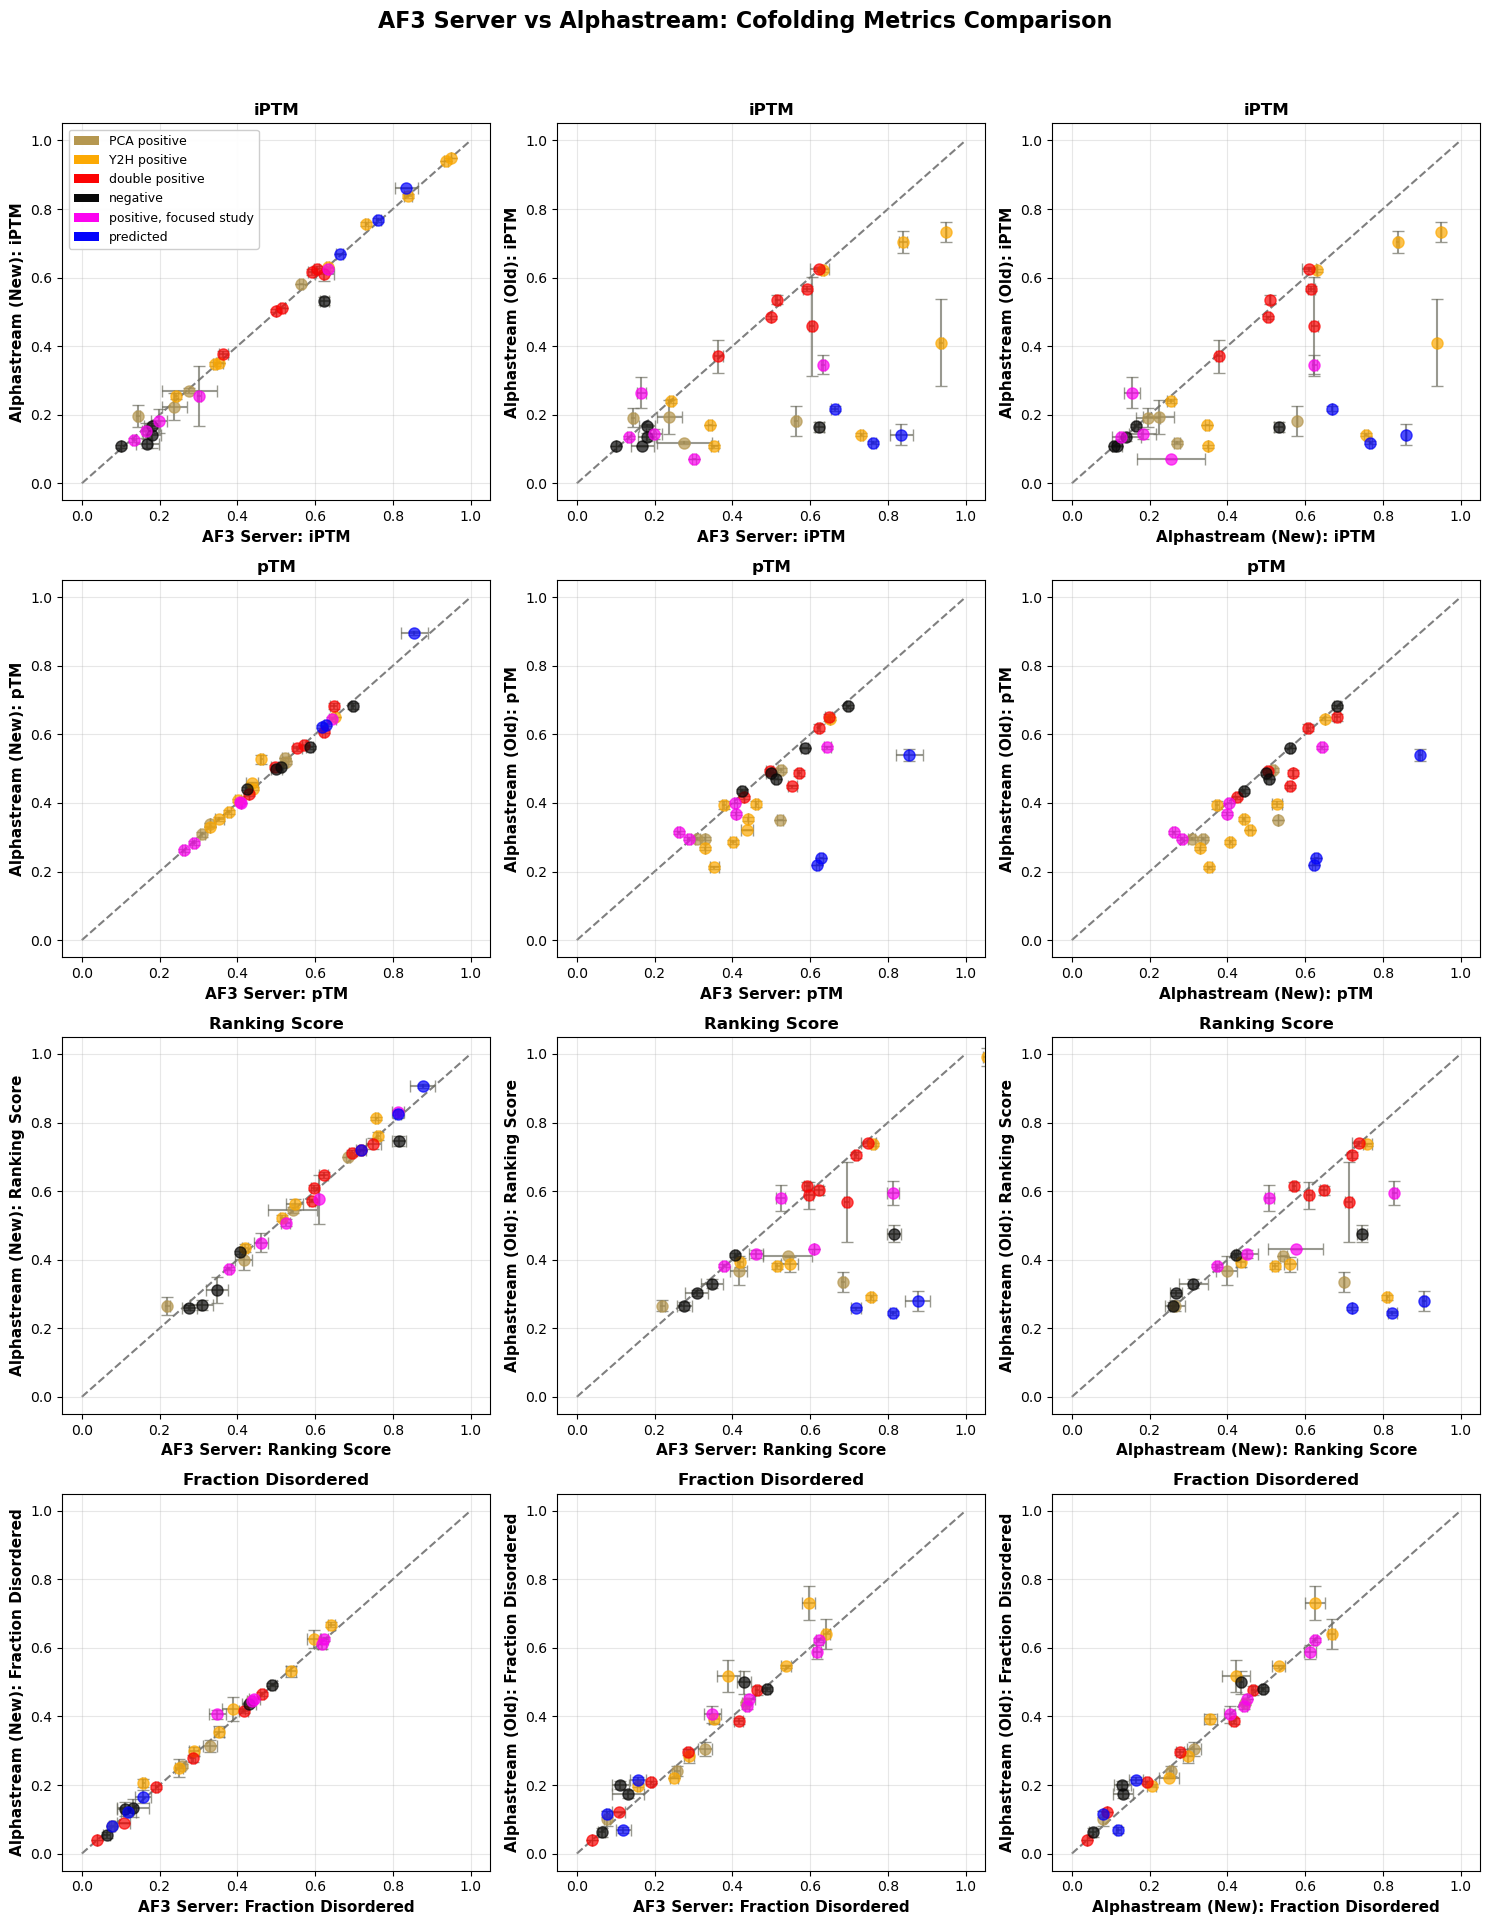

✓ Comparison plot saved to: C:\Users\heine\OneDrive - The Francis Crick Institute\Chemical Biology STP - PPI_Screen\Experimental data\small_control_test\af3server_vs_alphastream_comparison.png


In [18]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Load interaction categories
REFERENCE_CSV = os.path.join(CRICK_BASE_DATA_DIR, "pombe_interaction_small_test_UNIPROT.csv")
reference_df = pd.read_csv(REFERENCE_CSV)

# Create a mapping of (uniprot_id_A, uniprot_id_B) to category
category_dict = {}
for _, row in reference_df.iterrows():
    key = (row['uniprot_id_A'].upper(), row['uniprot_id_B'].upper())
    category_dict[key] = row['Interaction Category']

# Add category column to comparison dataframe
ppi_comparison_df['Interaction_Category'] = ppi_comparison_df.apply(
    lambda row: category_dict.get((row['uniprot_ID_A'].upper(), row['uniprot_ID_B'].upper()), 'Unknown'),
    axis=1
)

# Create figure with 12 subplots (3x4)
fig, axes = plt.subplots(4, 3, figsize=(15, 20))
fig.suptitle('AF3 Server vs Alphastream: Cofolding Metrics Comparison', fontsize=16, fontweight='bold')

# Define the metrics to plot
metrics = [
    ('iptm', 'iPTM', 0),
    ('ptm', 'pTM', 1),
    ('ranking_score', 'Ranking Score', 2),
    ('fraction_disordered', 'Fraction Disordered', 3)
]

#(x_label, x_prefix, x_suffix, y_label, y_prefix, y_suffix)
comparison_list = [('AF3 Server', 'af3server', '','Alphastream (New)', 'alphastream','_new'),
                   ('AF3 Server', 'af3server', '','Alphastream (Old)', 'alphastream','_old'),
                   ('Alphastream (New)', 'alphastream','_new','Alphastream (Old)', 'alphastream','_old')]


# Create a comparison dataframe that only includes rows with all datasets
ppi_comparison_complete = ppi_comparison_df.copy()
ppi_comparison_complete = ppi_comparison_complete[
    (ppi_comparison_complete[f'af3server_mean_{metrics[0][0]}'].notna()) &
    (ppi_comparison_complete[f'alphastream_mean_{metrics[0][0]}_new'].notna()) &
    (ppi_comparison_complete[f'alphastream_mean_{metrics[0][0]}_old'].notna()) 
]

print(f"Plotting data for {len(ppi_comparison_complete)} protein pairs with all datasets\n")

# Color mapping for interaction categories
label_dict = {'predicted': '#0303fc',
'positive, focused study': '#fc03f0', 
'double positive': '#fc0303',
'Y2H positive': '#fca903', 
'PCA positive': '#b59750',
'negative': '#080808'
}

error_color = "#6E6E61"

# Get unique categories and sort them
unique_categories = sorted(ppi_comparison_complete['Interaction_Category'].unique())

for metric_name, metric_label, row_idx in metrics:
    for (comparison_index, (x_label, x_prefix, x_suffix, y_label, y_prefix, y_suffix)) in enumerate(comparison_list):
        ax = axes[row_idx, comparison_index]
    
        # Add diagonal line for perfect agreement first (so it's behind the points)
        min_val = 0
        max_val = 1
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, alpha=0.5, zorder=0)
        
        # Plot each category with its own color
        legend_elements = []
        for category in unique_categories:
            # Filter data for this category
            cat_data = ppi_comparison_complete[ppi_comparison_complete['Interaction_Category'] == category]
            
            # Get data
            x_mean = cat_data[f'{x_prefix}_mean_{metric_name}{x_suffix}']
            x_std = cat_data[f'{x_prefix}_std_{metric_name}{x_suffix}'].fillna(0)
            
            y_mean = cat_data[f'{y_prefix}_mean_{metric_name}{y_suffix}']
            y_std = cat_data[f'{y_prefix}_std_{metric_name}{y_suffix}'].fillna(0)
            
            # Remove any rows with NaN values
            valid_idx = (x_mean.notna()) & (y_mean.notna())
            x_mean = x_mean[valid_idx]
            x_std = x_std[valid_idx]
            y_mean = y_mean[valid_idx]
            y_std = y_std[valid_idx]
            
            # Get color for this category
            point_color = label_dict.get(category, '#808080')
            
            # Plot error bars (whiskers) with category-specific color
            ax.errorbar(x_mean, y_mean, 
                        xerr=x_std, yerr=y_std,
                        fmt='o', markersize=8, elinewidth=1.5, capsize=4,
                        color=point_color, ecolor=error_color, alpha=0.7,
                        zorder=2)
            
            # Add to legend
            legend_elements.append(Patch(facecolor=point_color, label=category))
        
        # Add legend only to the top left plot
        if ((row_idx == 0) & (comparison_index==0)):
            ax.legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.95)
        
        # Labels and formatting
        ax.set_xlabel(f'{x_label}: {metric_label}', fontsize=11, fontweight='bold')
        ax.set_ylabel(f'{y_label}: {metric_label}', fontsize=11, fontweight='bold')
        ax.set_title(metric_label, fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
        
        # # Print summary statistics for this metric
        # print(f"{metric_label}:")
        # for category in unique_categories:
        #     cat_data = ppi_comparison_complete[ppi_comparison_complete['Interaction_Category'] == category]
        #     af3_mean = cat_data[f'af3server_mean_{metric_name}']
        #     alphastream_mean = cat_data[f'alphastream_mean_{metric_name}']
        #     valid_idx = (af3_mean.notna()) & (alphastream_mean.notna())
        #     if valid_idx.sum() > 0:
        #         print(f"  {category}: n={valid_idx.sum()}")
        # print()

plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

# Save figure
fig_output_path = os.path.join(CRICK_BASE_DATA_DIR, "af3server_vs_alphastream_comparison.png")
fig.savefig(fig_output_path, dpi=300, bbox_inches='tight')
print(f"✓ Comparison plot saved to: {fig_output_path}")


# MSA comparison
Based on the FAQ, it seems that the root of this problem might be from a deeper MSAon the alphafold server side https://alphafoldserver.com/faq#why-might-multiple-sequence-alignments-differ-between-alphafold-3-and-alphafold-server 

What is the difference between the MSAs for these two runs? 

# Extract MSAs from Alphastream Data

Extract Multiple Sequence Alignments (MSAs) from AlphaFold3 data files for comparison between installations.


In [13]:
# Extract MSAs for all Alphastream protein pairs

print("Extracting MSAs from Alphastream data files...\n")

msa_extraction_summary = {
    'total_pairs': 0,
    'successful': 0,
    'failed': 0,
    'errors': []
}

# Scan for all pair directories in ALPHASTREAM_DIR
alphastream_path = Path(ALPHASTREAM_DIR)

for pair_folder in sorted(alphastream_path.iterdir()):
    if not pair_folder.is_dir():
        continue
    
    folder_name = pair_folder.name
    
    # Check if this is a pair folder (starts with 'pair_')
    if not folder_name.startswith('pair_'):
        continue
    
    msa_extraction_summary['total_pairs'] += 1
    
    try:
        print(f"Processing: {folder_name}")
        usg.extract_msas_from_af3_data(str(pair_folder))
        msa_extraction_summary['successful'] += 1
        print()
    except Exception as e:
        msa_extraction_summary['failed'] += 1
        error_msg = f"{folder_name}: {str(e)}"
        msa_extraction_summary['errors'].append(error_msg)
        print(f"✗ Error: {error_msg}\n")

# Print summary
print(f"\n{'='*70}")
print("MSA EXTRACTION SUMMARY")
print(f"{'='*70}")
print(f"Total pair directories processed: {msa_extraction_summary['total_pairs']}")
print(f"Successfully extracted MSAs: {msa_extraction_summary['successful']}")
print(f"Failed extractions: {msa_extraction_summary['failed']}")

if msa_extraction_summary['errors']:
    print(f"\nErrors encountered:")
    for error in msa_extraction_summary['errors']:
        print(f"  - {error}")
else:
    print(f"\n✓ All MSAs extracted successfully!")


Extracting MSAs from Alphastream data files...

Processing: pair_01_Q9UTC2_Q1MTR0
✓ Saved: pair_01_Q9UTC2_Q1MTR0_unpaired_msa_chains_a.a3m
✓ Saved: pair_01_Q9UTC2_Q1MTR0_paired_msa_chains_a.a3m
✓ Saved: pair_01_Q9UTC2_Q1MTR0_unpaired_msa_chains_b.a3m
✓ Saved: pair_01_Q9UTC2_Q1MTR0_paired_msa_chains_b.a3m
✓ Extracted MSAs for pair_01_Q9UTC2_Q1MTR0

Processing: pair_02_P87155_Q9Y7Z4
✓ Saved: pair_02_P87155_Q9Y7Z4_unpaired_msa_chains_a.a3m
✓ Saved: pair_02_P87155_Q9Y7Z4_paired_msa_chains_a.a3m
✓ Saved: pair_02_P87155_Q9Y7Z4_unpaired_msa_chains_b.a3m
✓ Saved: pair_02_P87155_Q9Y7Z4_paired_msa_chains_b.a3m
✓ Extracted MSAs for pair_02_P87155_Q9Y7Z4

Processing: pair_03_O60082_Q6LA55
✓ Saved: pair_03_O60082_Q6LA55_unpaired_msa_chains_a.a3m
✓ Saved: pair_03_O60082_Q6LA55_paired_msa_chains_a.a3m
✓ Saved: pair_03_O60082_Q6LA55_unpaired_msa_chains_b.a3m
✓ Saved: pair_03_O60082_Q6LA55_paired_msa_chains_b.a3m
✓ Extracted MSAs for pair_03_O60082_Q6LA55

Processing: pair_04_O94687_P40235
✓ Saved: pai

In [11]:
# Validate extracted MSA files and display summary
print("Validating extracted MSA files...\n")

msa_validation = {
    'total_pairs': 0,
    'pairs_with_all_msas': 0,
    'pairs_with_partial_msas': 0,
    'pairs_with_no_msas': 0,
    'total_msa_files': 0,
    'file_sizes': []
}

alphastream_path = Path(ALPHASTREAM_DIR)

for pair_folder in sorted(alphastream_path.iterdir()):
    if not pair_folder.is_dir() or not pair_folder.name.startswith('pair_'):
        continue
    
    msa_validation['total_pairs'] += 1
    
    msas_dir = pair_folder / 'msas'
    
    if not msas_dir.exists():
        msa_validation['pairs_with_no_msas'] += 1
        continue
    
    # Count and check MSA files
    msa_files = list(msas_dir.glob('*.a3m'))
    msa_validation['total_msa_files'] += len(msa_files)
    
    if len(msa_files) == 4:
        msa_validation['pairs_with_all_msas'] += 1
    elif len(msa_files) > 0:
        msa_validation['pairs_with_partial_msas'] += 1
    else:
        msa_validation['pairs_with_no_msas'] += 1
    
    # Display files and sizes
    print(f"{pair_folder.name}/")
    for msa_file in sorted(msa_files):
        file_size = msa_file.stat().st_size
        msa_validation['file_sizes'].append(file_size)
        size_kb = file_size / 1024
        print(f"  - {msa_file.name} ({size_kb:.1f} KB)")

# Print validation summary
print(f"\n{'='*70}")
print("MSA FILE VALIDATION SUMMARY")
print(f"{'='*70}")
print(f"Total pair directories: {msa_validation['total_pairs']}")
print(f"Pairs with all 4 MSA files: {msa_validation['pairs_with_all_msas']}")
print(f"Pairs with partial MSA files: {msa_validation['pairs_with_partial_msas']}")
print(f"Pairs with no MSA files: {msa_validation['pairs_with_no_msas']}")
print(f"\nTotal MSA files created: {msa_validation['total_msa_files']}")

if msa_validation['file_sizes']:
    total_size = sum(msa_validation['file_sizes'])
    avg_size = total_size / len(msa_validation['file_sizes'])
    print(f"Average file size: {avg_size/1024:.1f} KB")
    print(f"Total storage: {total_size/(1024*1024):.1f} MB")

if msa_validation['pairs_with_all_msas'] == msa_validation['total_pairs']:
    print(f"\n✓ Success: All pairs have complete MSA files!")
else:
    print(f"\n⚠ Note: Some pairs may have missing or partial MSA files.")


Validating extracted MSA files...

pair_01_Q9UTC2_Q1MTR0/
  - pair_01_Q9UTC2_Q1MTR0_paired_msa_chains_a.a3m (0.1 KB)
  - pair_01_Q9UTC2_Q1MTR0_paired_msa_chains_b.a3m (0.2 KB)
  - pair_01_Q9UTC2_Q1MTR0_unpaired_msa_chains_a.a3m (0.1 KB)
  - pair_01_Q9UTC2_Q1MTR0_unpaired_msa_chains_b.a3m (0.2 KB)
pair_02_P87155_Q9Y7Z4/
  - pair_02_P87155_Q9Y7Z4_paired_msa_chains_a.a3m (0.2 KB)
  - pair_02_P87155_Q9Y7Z4_paired_msa_chains_b.a3m (0.7 KB)
  - pair_02_P87155_Q9Y7Z4_unpaired_msa_chains_a.a3m (0.2 KB)
  - pair_02_P87155_Q9Y7Z4_unpaired_msa_chains_b.a3m (0.7 KB)
pair_03_O60082_Q6LA55/
  - pair_03_O60082_Q6LA55_paired_msa_chains_a.a3m (0.3 KB)
  - pair_03_O60082_Q6LA55_paired_msa_chains_b.a3m (2.6 KB)
  - pair_03_O60082_Q6LA55_unpaired_msa_chains_a.a3m (0.3 KB)
  - pair_03_O60082_Q6LA55_unpaired_msa_chains_b.a3m (2.6 KB)
pair_04_O94687_P40235/
  - pair_04_O94687_P40235_paired_msa_chains_a.a3m (0.5 KB)
  - pair_04_O94687_P40235_paired_msa_chains_b.a3m (0.4 KB)
  - pair_04_O94687_P40235_unpaired_